# EnlightenGAN contrast enhancement (BTXRD, deep learning)
Enhances the contrast of every X-ray with **EnlightenGAN**, a GAN-based deep learning method, **at its full size** (2440 x 2440), and only then makes it 512 x 512 (the same way as notebook 07). Everything else is the same as in the classical notebooks.
The new images are saved as PNG in **`BTXRD_enlightengan_512.zip`**. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before. The original data is only read, never changed.

**EnlightenGAN** (Jiang et al., 2021, *EnlightenGAN: Deep Light Enhancement without Paired Supervision*, IEEE Transactions on Image Processing) is a GAN that learned to brighten dark images. It was trained on everyday photos, not on X-rays, and it is not trained again here. This notebook uses the authors' trained model in the form converted by github.com/arsenyinfo/EnlightenGAN-inference (`enlighten.onnx`), and uses it as in that code: the X-ray as a 3-channel image, pixels 0-1, filled up to a size that divides by 16. The 3 output channels are averaged back to one gray image. The supervisor's guide lists GAN-based enhancement as a deep learning method for contrast.

**Expect it to make most X-rays worse, not better.** This was measured before this notebook was written, on 40 tumor X-rays from the train images:

| Method | Tumor contrast (CII, above 1 = better) | Pixels newly white | Average brightness (originally 92) |
|---|---|---|---|
| **EnlightenGAN** | **0.61** | **4.2%** | **184** |
| URetinex-Net, strength 2 (fewest new white pixels) | 0.39 | 4.4% | 188 |
| URetinex-Net, strength 4 (best CII) | 0.60 | 9.5% | 174 |

Both models were made to brighten dark photos, and an X-ray is not a dark photo. EnlightenGAN reveals very dim X-rays, but it washes out the bone in normal ones. It is used because it was the better of the two and needs no strength setting. The 3 models trained on these images will show what this means for classification.

**Only the box around the X-ray goes through the network** (plus a margin of 32 pixels). Outside the box the image stays as it is.

Time: about 1-2 hours on a T4 GPU (estimated, not measured on a T4).
## Before you run
1. **In Google Drive**, the folder `BTXRD` (in *My Drive*) must hold `BTXRD_full.zip` and `BTXRD_512.zip`. You already uploaded them for the noise notebooks.
2. **In Colab**: *Runtime > Change runtime type > T4 GPU*, then *Run all*, and allow access to Google Drive.
3. **If Colab disconnects**, just *Run all* again: every finished image is already saved in Drive (folder `BTXRD/BTXRD_enlightengan_512`) and is skipped.
4. **At the end**, download `BTXRD_enlightengan_512.zip` and `BTXRD_enlightengan_512_full_size_scores.csv` (last cell, or from the Drive folder `BTXRD`) and put them in this folder, next to this notebook. Then save this notebook with its outputs: *File > Download > Download .ipynb*. (In Safari, first untick *Settings > General > Open "safe" files after downloading*, or the zip gets unpacked.)

## Settings

In [1]:
import io
import json
import os
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"           # needed for repeatable GPU results (set before torch starts)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from google.colab import drive

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/BTXRD")               # your Google Drive folder with the 2 zips
FULL_ZIP = DRIVE / "BTXRD_full.zip"                        # the full-size images: train, validation, test, Annotations (only read)
OLD_ZIP_DRIVE = DRIVE / "BTXRD_512.zip"                    # the baseline zip (only read)
LOCAL = Path("/content/btxrd_full")                        # the full-size images are unzipped here (the fast local disk)
OLD_ZIP = Path("/content/BTXRD_512.zip")                   # a local copy of the baseline zip
NAME = "BTXRD_enlightengan_512"                            # the name of the new zip and of the folder inside it
OUT_DIR = DRIVE / NAME                                     # the finished 512 x 512 PNGs, kept in Drive, so a disconnect loses nothing
NEW_ZIP = Path("/content") / (NAME + ".zip")               # the new zip, made at the end (and copied to Drive)
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
MARGIN = 32          # EnlightenGAN: 32 pixels around the X-ray box
BLOCK = 16           # EnlightenGAN: the size of the image must divide by 16
WHITE = 250          # pixels at or above this count as white
CHECK_IMAGES = 40    # the check before all images: the same 40 train tumor X-rays as in the test
MODEL_URL = "https://raw.githubusercontent.com/arsenyinfo/EnlightenGAN-inference/6b68a71f0b973912cffad25bff243b28530de823/enlighten_inference/enlighten.onnx"   # the trained model
MODEL_FILE = Path("/content/enlighten.onnx")
MODEL_BYTES = 34584643   # the exact size of that file
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)
RING_FULL = 48       # CII at full size: the same ring, 48 pixels wide on the 2440 x 2440 image (10 x 2440 / 512)
FULL_SCORES = DRIVE / (NAME + "_full_size_scores.csv")     # the full-size scores, one line per image, kept in Drive
SEED = 42            # makes the random parts the same every time

Mounted at /content/drive


## GPU, settings for repeatable results, and the data
Checks the GPU, unzips the full-size images to the fast local disk, and finds the data folders.

In [2]:
assert torch.cuda.is_available(), "No GPU: choose Runtime > Change runtime type > T4 GPU, then run again"
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True                  # the same GPU calculations every time
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False                    # full 32-bit precision, also on newer GPUs
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)   # repeatable where possible (only warns otherwise)

for f in [FULL_ZIP, OLD_ZIP_DRIVE]:
    assert f.exists(), f"Upload {f.name} to the Google Drive folder {DRIVE} first"

if not (LOCAL / "unzipped.txt").exists():                  # skipped when this runtime already has them
    shutil.rmtree(LOCAL, ignore_errors=True)
    local_zip = Path("/content/BTXRD_full.zip")
    shutil.copy(FULL_ZIP, local_zip)                       # copy from Drive first: the local disk is much faster
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(LOCAL)
    local_zip.unlink()
    (LOCAL / "unzipped.txt").write_text("done")
if not OLD_ZIP.exists():
    shutil.copy(OLD_ZIP_DRIVE, OLD_ZIP)


def find_data(folder):
    for annotations in sorted(folder.rglob("Annotations")):
        root = annotations.parent
        if "__MACOSX" not in root.parts and all((root / split).is_dir() for split in SPLITS):
            return root
    raise FileNotFoundError("BTXRD_full.zip must hold the folders train, validation, test and Annotations")


DATA = find_data(LOCAL)                                    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                         # tumor outlines (only read)
print("Full-size images:", DATA)

GPU: Tesla T4
Full-size images: /content/btxrd_full


## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [3]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        if path.name.startswith("._"):
            continue                                           # hidden Mac files, not X-rays
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [4]:
old_zip = zipfile.ZipFile(OLD_ZIP)                         # kept open: the baseline images are read from it later
old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
             for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, make an image 512 x 512 (the same way as notebook 07), read a baseline image, and find the X-ray inside the black square.

In [5]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def baseline(item):
    path = f"BTXRD_512/{item['split']}/{item['label']}/{item['image']}.png"
    return np.array(Image.open(io.BytesIO(old_zip.read(path))))   # the baseline image the models were trained on


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Check: Colab makes 512 x 512 images exactly like the baseline
The baseline images were made on the Mac. If Colab's image library shrank images even a little differently, part of the difference would come from that and not from the method. So 25 images are shrunk here and must be exactly the same as in `BTXRD_512.zip`.

In [6]:
sample = images.sample(25, random_state=SEED)
same = [np.array_equal(shrink(load(item["path"])), baseline(item)) for _, item in sample.iterrows()]
print("Made 512 x 512 exactly like BTXRD_512.zip:", sum(same), "of", len(same))
assert all(same), "This Pillow version resizes differently: run  !pip install pillow==12.3.0  then Runtime > Restart, and run again"

Made 512 x 512 exactly like BTXRD_512.zip: 25 of 25


## The EnlightenGAN model
Installs the GPU version of ONNX Runtime, the tool that runs this model, and loads the trained model. The notebook stops here if the model is not on the GPU.

In [7]:
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

# The GPU version of ONNX Runtime must fit Colab's CUDA: 13.x works with the newest version, 12.x with version 1.26 (the last one built for CUDA 12.8)
package = "onnxruntime-gpu" if torch.version.cuda.startswith("13") else "onnxruntime-gpu==1.26.*"
try:
    version("onnxruntime-gpu")                                 # already installed in this runtime
except PackageNotFoundError:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-q", "-y", "onnxruntime"], check=False)   # the normal version must not get in the way
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

import onnxruntime as ort

if not MODEL_FILE.exists():
    torch.hub.download_url_to_file(MODEL_URL, str(MODEL_FILE))  # stops with an error if the download fails
assert MODEL_FILE.stat().st_size == MODEL_BYTES, "enlighten.onnx is not the expected file"

session = ort.InferenceSession(str(MODEL_FILE), providers=[("CUDAExecutionProvider", {
    "arena_extend_strategy": "kSameAsRequested",               # every X-ray has another size: take only the GPU memory that is needed
    "cudnn_conv_algo_search": "DEFAULT"})])                    # no speed test for every new size
print("ONNX Runtime", ort.__version__, "| CUDA of PyTorch", torch.version.cuda, "| running on", session.get_providers())
assert session.get_providers()[0] == "CUDAExecutionProvider", "EnlightenGAN is not on the GPU, which would take many hours: send this output to Claude"


def enlightengan(image):
    top, bottom, left, right = xray_box(image)                 # the box around the X-ray ...
    top, left = max(top - MARGIN, 0), max(left - MARGIN, 0)    # ... with a margin
    bottom, right = min(bottom + MARGIN, image.shape[0]), min(right + MARGIN, image.shape[1])
    crop = image[top:bottom, left:right]
    height, width = crop.shape
    filled = np.pad(crop, ((0, (height // BLOCK + 1) * BLOCK - height), (0, (width // BLOCK + 1) * BLOCK - width)))   # zeros up to a size that divides by 16, as in the wrapper
    x = np.repeat(filled[None, None], 3, axis=1).astype(np.float32) / 255   # 1 x 3 x H x W, pixels 0-1
    y, = session.run(["output"], {"input": x})                 # the enhanced image, pixels -1 to 1
    y = np.clip((y[0].mean(axis=0) + 1) / 2 * 255, 0, 255).round().astype(np.uint8)[:height, :width]   # 3 channels to 1 gray image, back to 0-255
    result = image.copy()                                      # outside the box the image stays as it is
    result[top:bottom, left:right] = y
    return result

100%|██████████| 33.0M/33.0M [00:00<00:00, 109MB/s]


ONNX Runtime 1.31.1 | CUDA of PyTorch 13.0 | running on ['CUDAExecutionProvider', 'CPUExecutionProvider']


## Measuring functions
The same functions as in the classical notebooks.
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [8]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Measuring functions at full size
The same tumor outline and ring, but on the 2440 x 2440 image: the outline is not made smaller, and the ring is 48 pixels wide (the same area as the 10-pixel ring at 512 x 512), as in the classical `*_full_size_scores` notebooks.

In [9]:
def tumor_mask_full(name, size):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = size[1] / annotation["imageWidth"]                 # 1.0: the outline was drawn on the 2440 x 2440 image
    mask = np.zeros(size, dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around_full(tumor, before):
    kernel = np.ones((2 * RING_FULL + 1, 2 * RING_FULL + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING_FULL pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background

## Check: the same behaviour as in the test
The same 40 train tumor X-rays as in the test before this notebook was written. The numbers must be close to the test (on the GPU, tiny differences are normal). If not, the notebook stops here.

In [10]:
picked = images[(images["split"] == "train") & (images["label"] == "tumor")].sample(CHECK_IMAGES, random_state=SEED)
tried = []
for _, item in picked.iterrows():
    raw = load(item["path"])
    full = enlightengan(raw)
    xray = raw > BLACK
    tumor = tumor_mask_full(item["image"], raw.shape)
    tried.append({"CII": cii(raw, full, tumor, ring_around_full(tumor, raw)),
                  "new white pixels (%)": 100 * ((full[xray] >= WHITE).mean() - (raw[xray] >= WHITE).mean()),
                  "brightness": full[xray].mean(), "original brightness": raw[xray].mean()})
tried = pd.DataFrame(tried)
check = {"CII": tried["CII"].median(), "new white pixels (%)": tried["new white pixels (%)"].mean(),
         "brightness": tried["brightness"].mean(), "original brightness": tried["original brightness"].mean()}
print({name: round(value, 3) for name, value in check.items()})
print("Measured before this notebook was written: CII 0.61, new white pixels 4.2, brightness 184.2, original brightness 92.1")
assert abs(check["CII"] - 0.61) < 0.03 and abs(check["new white pixels (%)"] - 4.2) < 0.5 and abs(check["brightness"] - 184.2) < 1.5, "The model behaves differently here than in the test: send this output to Claude"

{'CII': 0.61, 'new white pixels (%)': np.float64(4.197), 'brightness': np.float64(184.237), 'original brightness': np.float64(92.128)}
Measured before this notebook was written: CII 0.61, new white pixels 4.2, brightness 184.2, original brightness 92.1


## Before and after: 2 normal, 2 benign, 2 malignant
Both at 512 x 512, the size the models see. Before = the baseline image (the same as in `BTXRD_512.zip`).

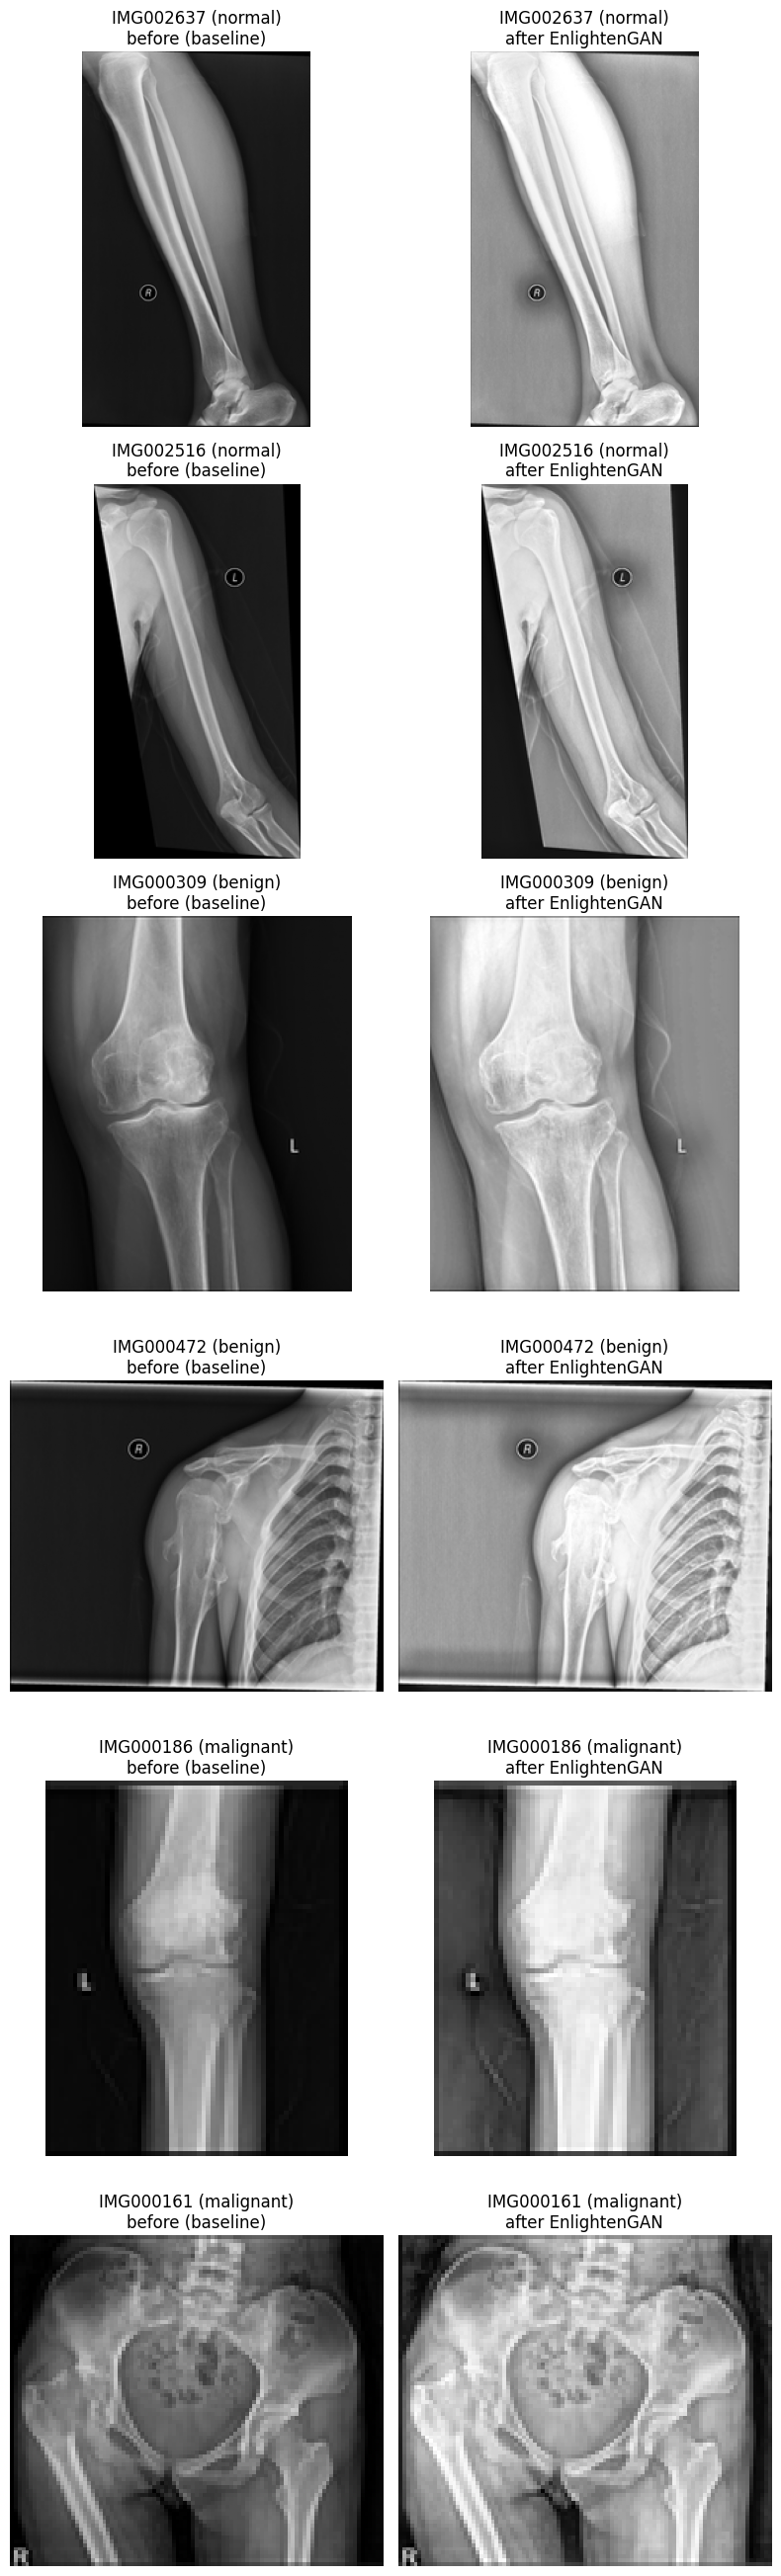

In [11]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "after EnlightenGAN"]

fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    before = baseline(pick)                                    # the baseline image
    after = shrink(enlightengan(load(pick['path'])))           # EnlightenGAN on the full image, then 512 x 512
    top, bottom, left, right = xray_box(before)                # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, [before, after], titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Make every image
For every image: EnlightenGAN on the full image, then 512 x 512, then saved as PNG in the Drive folder `BTXRD/BTXRD_enlightengan_512`.
While the full-size result is there, its **full-size scores** are measured too (the full image after EnlightenGAN against the original full image) and saved as one line per image in `BTXRD/BTXRD_enlightengan_512_full_size_scores.csv`. So the method runs only once.
Images that are already done are skipped, so after a disconnect this continues where it stopped.

In [12]:
def png_path(item):
    return OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")


def scored_images():
    if not FULL_SCORES.exists():
        return set()
    return set(pd.read_csv(FULL_SCORES)["image"])             # images that already have their full-size scores


scored = scored_images()
todo = [item for _, item in images.iterrows() if not png_path(item).exists() or item["image"] not in scored]
print(len(images) - len(todo), "images already done,", len(todo), "to do")

start = time.time()
for n, item in enumerate(todo, start=1):
    raw = load(item["path"])                                   # the original X-ray at full size
    full = enlightengan(raw)                                   # EnlightenGAN on the full image (2440 x 2440)
    after = shrink(full)                                       # then 512 x 512

    psnr, ssim = psnr_ssim(raw, full)                          # full-size scores: the full image after the method vs the original
    row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
    if item["label"] == "tumor":
        tumor = tumor_mask_full(item["image"], raw.shape)
        row["CII"] = cii(raw, full, tumor, ring_around_full(tumor, raw))
    pd.DataFrame([row]).to_csv(FULL_SCORES, mode="a", header=not FULL_SCORES.exists(), index=False)   # one line per image, in Drive

    target = png_path(item)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(".tmp")
    Image.fromarray(after).save(temporary, format="PNG")
    os.replace(temporary, target)                              # renamed only when complete, so a half-written image is never kept

    if n % 100 == 0 or n == len(todo):
        minutes_left = (time.time() - start) / n * (len(todo) - n) / 60
        print(f"{n} of {len(todo)} done, about {minutes_left:.0f} minutes left")

done = sum(1 for _, item in images.iterrows() if png_path(item).exists())
scored = scored_images()
print(done, "of", len(images), "images are in", OUT_DIR, "|", len(scored & set(images["image"])), "have full-size scores")
assert done == len(images) and set(images["image"]) <= scored, "not all images are done: run this cell again"

0 images already done, 3723 to do
100 of 3723 done, about 40 minutes left
200 of 3723 done, about 42 minutes left
300 of 3723 done, about 42 minutes left
400 of 3723 done, about 40 minutes left
500 of 3723 done, about 39 minutes left
600 of 3723 done, about 39 minutes left
700 of 3723 done, about 38 minutes left
800 of 3723 done, about 37 minutes left
900 of 3723 done, about 35 minutes left
1000 of 3723 done, about 34 minutes left
1100 of 3723 done, about 33 minutes left
1200 of 3723 done, about 30 minutes left
1300 of 3723 done, about 28 minutes left
1400 of 3723 done, about 26 minutes left
1500 of 3723 done, about 25 minutes left
1600 of 3723 done, about 24 minutes left
1700 of 3723 done, about 23 minutes left
1800 of 3723 done, about 22 minutes left
1900 of 3723 done, about 21 minutes left
2000 of 3723 done, about 20 minutes left
2100 of 3723 done, about 18 minutes left
2200 of 3723 done, about 17 minutes left
2300 of 3723 done, about 16 minutes left
2400 of 3723 done, about 15 minu

## Make the zip
Puts all images in `BTXRD_enlightengan_512.zip` (`BTXRD_enlightengan_512/split/label/name.png`), the same layout as `BTXRD_512.zip`, and also copies it to Drive.

In [13]:
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for _, item in images.iterrows():
        source = OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")
        new_zip.write(source, f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png")

shutil.copy(NEW_ZIP, DRIVE / NEW_ZIP.name)                     # also keep the zip in Google Drive
print(len(images), "images saved in", NEW_ZIP, "and in", DRIVE / NEW_ZIP.name)

3723 images saved in /content/BTXRD_enlightengan_512.zip and in /content/drive/MyDrive/BTXRD/BTXRD_enlightengan_512.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [14]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_enlightengan_512/test/normal 280
BTXRD_enlightengan_512/test/tumor 279
BTXRD_enlightengan_512/train/normal 1306
BTXRD_enlightengan_512/train/tumor 1300
BTXRD_enlightengan_512/validation/normal 280
BTXRD_enlightengan_512/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 86 MB


## Measure every image at 512 x 512
PSNR, SSIM and CII of every image in the new zip against its baseline image, as in the classical notebooks. CII is only for tumor images.

In [15]:
rows = []
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    for _, item in images.iterrows():
        before = baseline(item)                                # the baseline image
        after = np.array(Image.open(io.BytesIO(new_zip.read(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png"))))

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

scores = pd.DataFrame(rows)
print(len(scores), "images measured")

3723 images measured


## Results at 512 x 512
The middle value (median) of each score: the image after EnlightenGAN compared with the baseline image. CII only counts the tumor images.

In [16]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

,0
PSNR,8.716
SSIM,0.527
CII,0.575


## Results at full size
The middle value (median) of each score at full size: the full image after EnlightenGAN compared with the original full image. CII only counts the tumor images.

In [17]:
full_scores = pd.read_csv(FULL_SCORES).drop_duplicates("image", keep="last")   # one line per image (a disconnect can repeat one)
full_scores = full_scores[full_scores["image"].isin(images["image"])]
print(len(full_scores), "images with full-size scores")
assert len(full_scores) == len(images)
full_scores[["PSNR", "SSIM", "CII"]].median().round(3)

3723 images with full-size scores


,0
PSNR,8.698
SSIM,0.547
CII,0.583


## Download the zip and the full-size scores

In [18]:
from google.colab import files                                 # imported again: the zip check above uses the name "files" for its list

files.download(str(NEW_ZIP))                                   # or download both from the Google Drive folder BTXRD
files.download(str(FULL_SCORES))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>